## Import required libraries

In [ ]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models, callbacks

## Read in the insurance dataset

In [ ]:
insurance = pd.read_csv(r"C:\Users\Admin\Desktop\Machine_Learning\Activity_2\insurance.csv")

## Check out the insurance dataset

In [ ]:
insurance.head()

## Turn all categories into numbers

In [ ]:
ct = make_column_transformer(
(MinMaxScaler(), ["age", "bmi", "children"]),
(OneHotEncoder(handle_unknown="ignore"), ["sex", "smoker", "region"])
)
X = insurance.drop("charges", axis=1)
y = insurance["charges"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
ct.fit(X_train)
X_train_normal = ct.transform(X_train)
X_test_normal = ct.transform(X_test)

In [ ]:
X_train.loc(0)

In [ ]:
X_train_normal[0]

In [ ]:
X_train_normal.shape, X_test_normal.shape

## Normalize the data and build the model

In [8]:
tf.random.set_seed(42)

insurance_model_1 = tf.keras.Sequential([
  tf.keras.layers.Input(shape=(X_train_normal.shape[1],)),
  tf.keras.layers.Dense(128, activation="relu"),
  tf.keras.layers.Dense(64, activation="relu"),
  tf.keras.layers.Dense(32, activation="relu"),
  tf.keras.layers.Dense(1)
])

insurance_model_1.compile(loss=tf.keras.losses.mae,
  optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
  metrics=['mae'])

history_1 = insurance_model_1.fit(X_train_normal, y_train, epochs=1000, verbose=0)

insurance_model_1_loss, insurance_model_1_mae = insurance_model_1.evaluate(X_test_normal, y_test)
insurance_model_1_loss, insurance_model_1_mae

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 1434.9243 - mae: 1434.9243


(1434.92431640625, 1434.92431640625)

Text(0.5, 0, 'epochs')

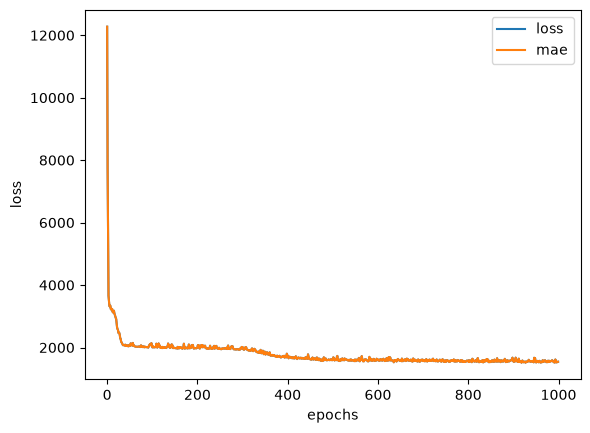

In [9]:
pd.DataFrame(history_1.history).plot()
plt.ylabel("loss")
plt.xlabel("epochs")

## Model No.2

In [10]:
tf.random.set_seed(42)

insurance_model_2 = tf.keras.Sequential([
  tf.keras.layers.Input(shape=(X_train_normal.shape[1],)),
  tf.keras.layers.Dense(128, activation="relu"),
  tf.keras.layers.Dense(64, activation="relu"),
  tf.keras.layers.Dense(32, activation="relu"),
  tf.keras.layers.Dense(16, activation="relu"),
  tf.keras.layers.Dense(1)
])

insurance_model_2.compile(loss=tf.keras.losses.mae,
  optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
  metrics=['mae'])

history_2 = insurance_model_2.fit(X_train_normal, y_train, epochs=500, verbose=0)
insurance_model_2_loss, insurance_model_2_mae = insurance_model_2.evaluate(X_test_normal, y_test)
insurance_model_2_loss, insurance_model_2_mae

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 1555.6107 - mae: 1555.6107  


(1555.6107177734375, 1555.6107177734375)

Text(0.5, 0, 'epochs')

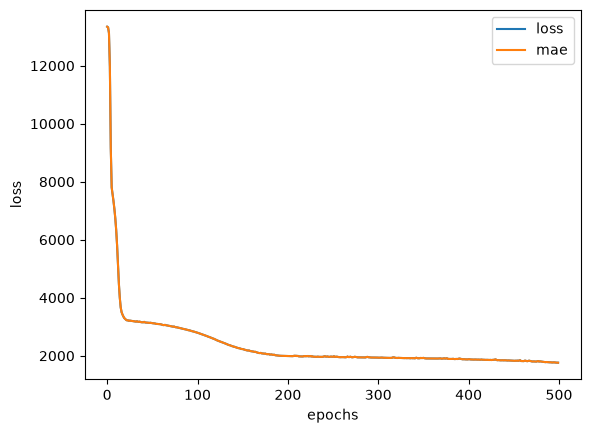

In [11]:
pd.DataFrame(history_2.history).plot()
plt.ylabel("loss")
plt.xlabel("epochs")

## Model No.3

In [12]:
y_scaler = MinMaxScaler()
y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1))

tf.random.set_seed(42)

insurance_model_3 = tf.keras.Sequential([
  tf.keras.layers.Input(shape=(X_train_normal.shape[1],)),
  tf.keras.layers.Dense(128, activation="relu"),
  tf.keras.layers.Dense(64, activation="relu"),
  tf.keras.layers.Dense(32, activation="relu"),
  tf.keras.layers.Dense(16, activation="relu"),
  tf.keras.layers.Dense(1)
])

insurance_model_3.compile(loss=tf.keras.losses.mae,
  optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
  metrics=['mae'])

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True)

history_3 = insurance_model_3.fit(X_train_normal, y_train_scaled,
                        validation_split=0.2,
                        batch_size=32,   
                        callbacks=[early_stop],
                        epochs=500,
                        verbose=0)

insurance_model_3_loss, insurance_model_3_mae = insurance_model_3.evaluate(X_test_normal, y_test_scaled)
insurance_model_3_loss, insurance_model_3_mae

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0264 - mae: 0.0264


(0.026441778987646103, 0.026441778987646103)

Text(0.5, 0, 'epochs')

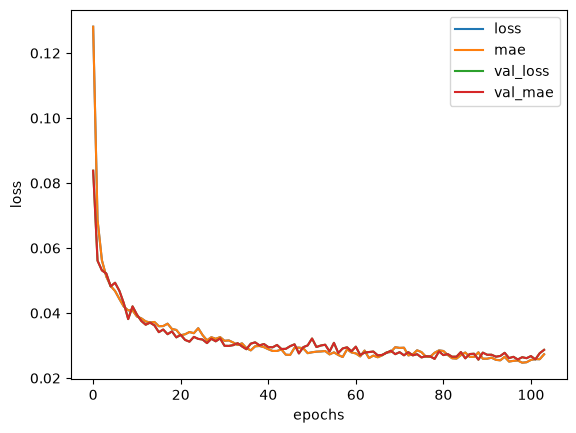

In [13]:
pd.DataFrame(history_3.history).plot()
plt.ylabel("loss")
plt.xlabel("epochs")